<a href="https://colab.research.google.com/github/saturnsz/project-machine-learning-f1/blob/main/project_machine_learning_f1_part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')

In [3]:
print("=== 1. INFORMASI DATA SEBELUM CLEANING ===")
df = pd.read_csv("/content/drive/MyDrive/winners_f1_1950_2025_v2.csv")
print(df.info())

=== 1. INFORMASI DATA SEBELUM CLEANING ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1142 entries, 0 to 1141
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         1142 non-null   object 
 1   continent    1142 non-null   object 
 2   grand_prix   1142 non-null   object 
 3   circuit      1142 non-null   object 
 4   winner_name  1142 non-null   object 
 5   team         1142 non-null   object 
 6   time         1142 non-null   object 
 7   laps         1142 non-null   float64
 8   year         1142 non-null   int64  
dtypes: float64(1), int64(1), object(7)
memory usage: 80.4+ KB
None


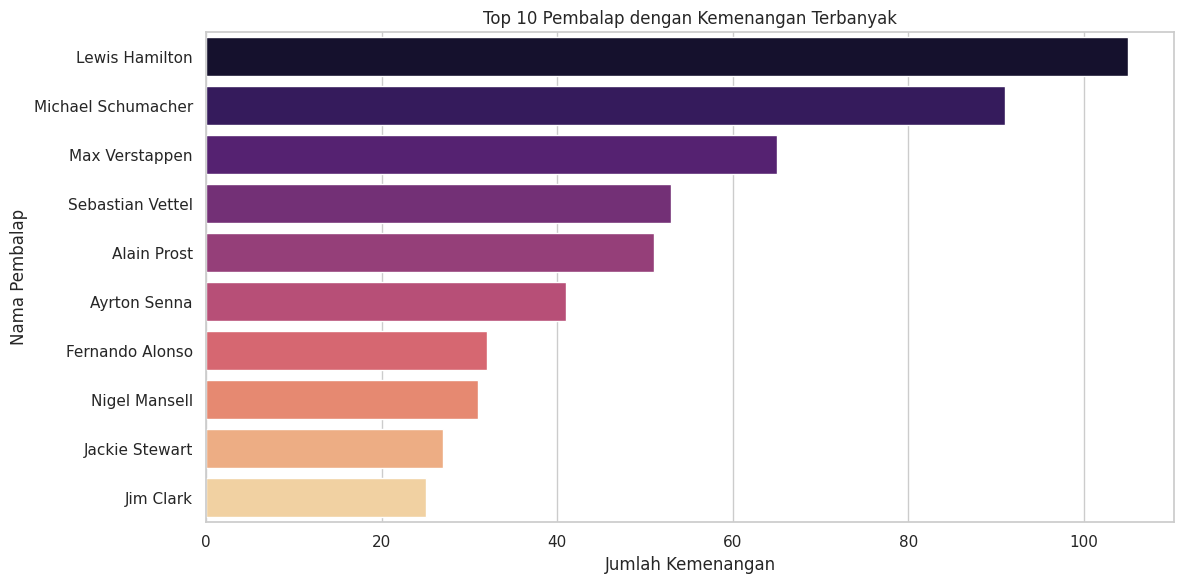

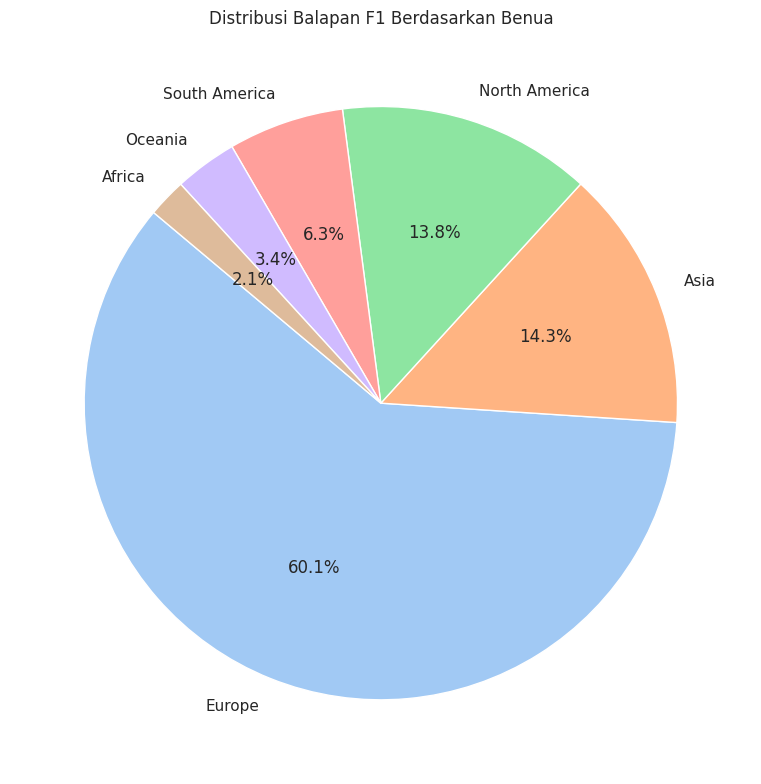

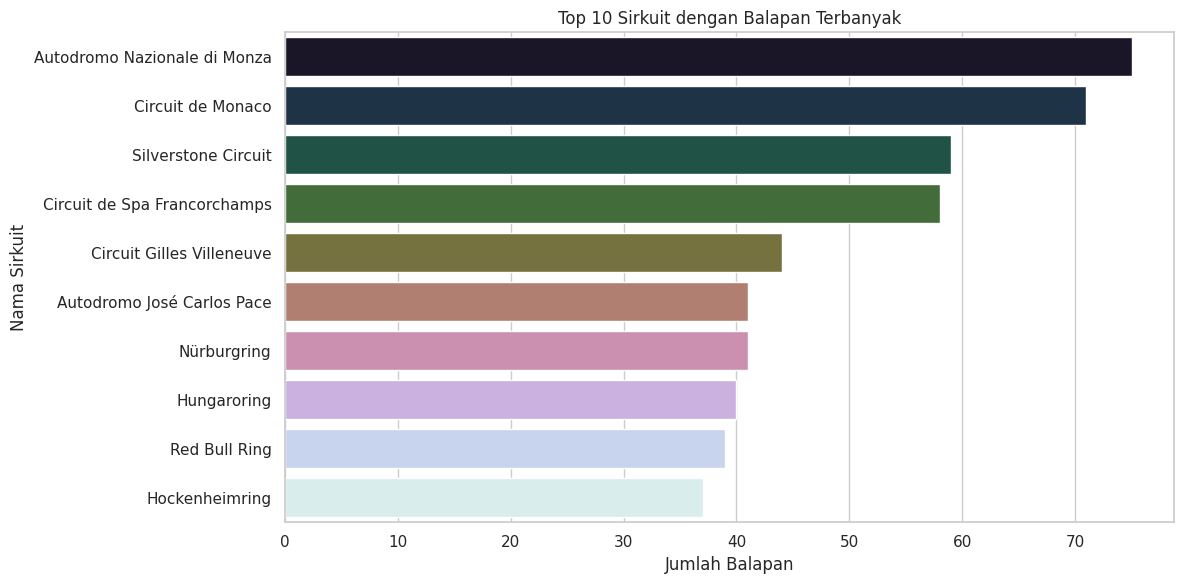

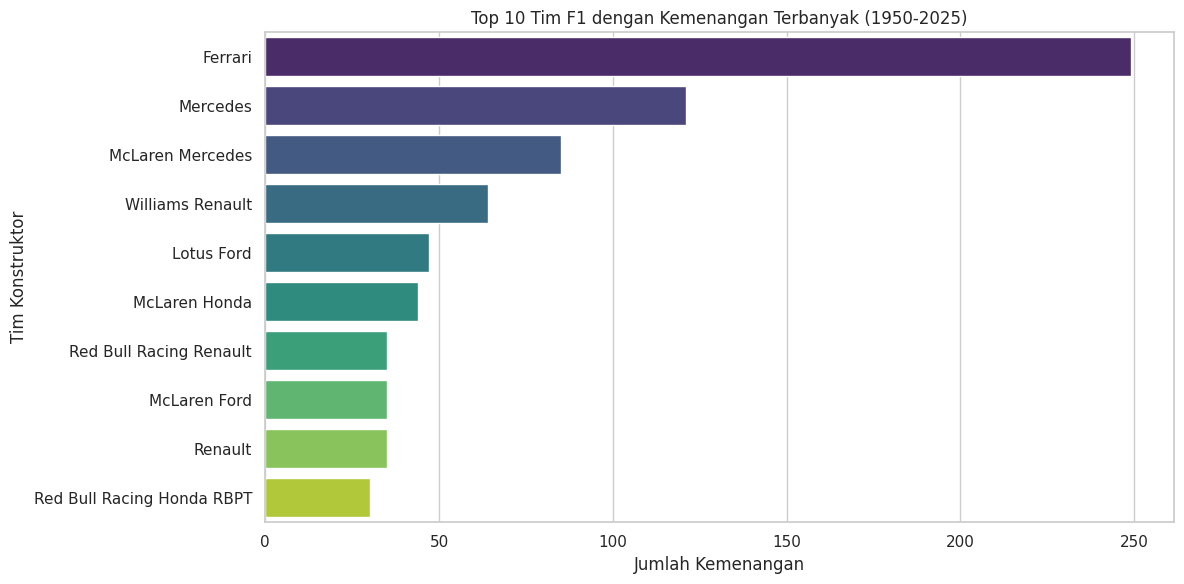

EDA plots generated successfully.


In [11]:
# Setup style
sns.set_theme(style="whitegrid")

# 1. Balapan per Tahun
plt.figure(figsize=(15, 5))
sns.histplot(data=df, x='year', bins=len(df['year'].unique()), kde=True, color='blue')
plt.title('Distribusi Jumlah Balapan F1 per Tahun (1950-2025)')
plt.xlabel('Tahun')
plt.ylabel('Jumlah Balapan')
plt.tight_layout()
plt.savefig('eda_year.png')
plt.close()

# 2. Top 10 Pembalap (Driver)
plt.figure(figsize=(12, 6))
top_drivers = df['winner_name'].value_counts().head(10)
sns.barplot(x=top_drivers.values, y=top_drivers.index, palette='magma')
plt.title('Top 10 Pembalap dengan Kemenangan Terbanyak')
plt.xlabel('Jumlah Kemenangan')
plt.ylabel('Nama Pembalap')
plt.tight_layout()
plt.savefig('eda_drivers.png')
plt.show()

# 3. Distribusi Balapan Berdasarkan Benua
plt.figure(figsize=(8, 8))
continent_counts = df['continent'].value_counts()
plt.pie(continent_counts.values, labels=continent_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Distribusi Balapan F1 Berdasarkan Benua')
plt.tight_layout()
plt.savefig('eda_continent.png')
plt.show()

# 4. Top 10 Sirkuit Paling Sering Digunakan
plt.figure(figsize=(12, 6))
top_circuits = df['circuit'].value_counts().head(10)
sns.barplot(x=top_circuits.values, y=top_circuits.index, palette='cubehelix')
plt.title('Top 10 Sirkuit dengan Balapan Terbanyak')
plt.xlabel('Jumlah Balapan')
plt.ylabel('Nama Sirkuit')
plt.tight_layout()
plt.savefig('eda_circuits.png')
plt.show()

# --- PLOT 5: Top 10 Tim F1 (Sesuai kode sebelumnya) ---
plt.figure(figsize=(12, 6))
top_teams = df['team'].value_counts().head(10)
sns.barplot(x=top_teams.values, y=top_teams.index, palette='viridis')
plt.title("Top 10 Tim F1 dengan Kemenangan Terbanyak (1950-2025)")
plt.xlabel("Jumlah Kemenangan")
plt.ylabel("Tim Konstruktor")
plt.tight_layout()
plt.show()

print("EDA plots generated successfully.")

In [7]:
print("\n=== 2. PREPROCESSING DATA ===")
# Target: Ambil Top 5 Tim, sisanya 'Other'
top_5_teams = df['team'].value_counts().head(5).index.tolist()
df_clean = df.copy()
df_clean['team_target'] = df_clean['team'].apply(lambda x: x if x in top_5_teams else 'Other')

# Fitur Prediktor
features = ['year', 'continent', 'circuit', 'grand_prix']
X = df_clean[features]
y = df_clean['team_target']

# Encoding target
le = LabelEncoder()
y_encoded = le.fit_transform(y)


=== 2. PREPROCESSING DATA ===


In [8]:
cat_features = ['continent', 'circuit', 'grand_prix']
num_features = ['year']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ])

# Pipeline dasar
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(random_state=42, eval_metric='mlogloss'))
])

In [9]:
print("\n=== 3. FINE TUNING DENGAN GRID SEARCH ===")
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Definisikan parameter yang ingin diuji (Gunakan prefix 'classifier__' karena ada di dalam pipeline)
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2]
}

# Setup GridSearchCV dengan Cross-Validation (cv=5)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1, # Gunakan semua core CPU agar lebih cepat
    verbose=1
)

print("Mulai proses Hyperparameter Tuning (ini mungkin memakan waktu beberapa saat)...")
grid_search.fit(X_train, y_train)

print("\nFine Tuning Selesai!")
print("Parameter Terbaik:", grid_search.best_params_)

# Ambil model terbaik hasil fine tuning
best_model = grid_search.best_estimator_


=== 3. FINE TUNING DENGAN GRID SEARCH ===
Mulai proses Hyperparameter Tuning (ini mungkin memakan waktu beberapa saat)...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Fine Tuning Selesai!
Parameter Terbaik: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 50}


In [10]:
print("\n=== 4. HASIL EVALUASI MODEL TERBAIK ===")
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Akurasi Model XGBoost (setelah tuning): {accuracy * 100:.2f}%\n")

target_names = le.inverse_transform(np.unique(y_encoded))
print("Classification Report:")


=== 4. HASIL EVALUASI MODEL TERBAIK ===
Akurasi Model XGBoost (setelah tuning): 62.45%

Classification Report:
